In [1]:
import torch

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [11]:
x = torch.linspace(-2, 2, 50).unsqueeze(1)

In [6]:
x

tensor([[-2.0000],
        [-1.9664],
        [-1.9328],
        [-1.8992],
        [-1.8655],
        [-1.8319],
        [-1.7983],
        [-1.7647],
        [-1.7311],
        [-1.6975],
        [-1.6639],
        [-1.6303],
        [-1.5966],
        [-1.5630],
        [-1.5294],
        [-1.4958],
        [-1.4622],
        [-1.4286],
        [-1.3950],
        [-1.3613],
        [-1.3277],
        [-1.2941],
        [-1.2605],
        [-1.2269],
        [-1.1933],
        [-1.1597],
        [-1.1261],
        [-1.0924],
        [-1.0588],
        [-1.0252],
        [-0.9916],
        [-0.9580],
        [-0.9244],
        [-0.8908],
        [-0.8571],
        [-0.8235],
        [-0.7899],
        [-0.7563],
        [-0.7227],
        [-0.6891],
        [-0.6555],
        [-0.6218],
        [-0.5882],
        [-0.5546],
        [-0.5210],
        [-0.4874],
        [-0.4538],
        [-0.4202],
        [-0.3866],
        [-0.3529],
        [-0.3193],
        [-0.2857],
        [-0.

In [17]:
# Créer un bruit aléatoire pour les données
noise = 0.6*torch.randn_like(x)
y = 3 * x + 2 + noise

In [8]:
import matplotlib.pyplot as plt
import numpy as np

In [9]:
import numpy as np
print(np.__version__)

1.26.4


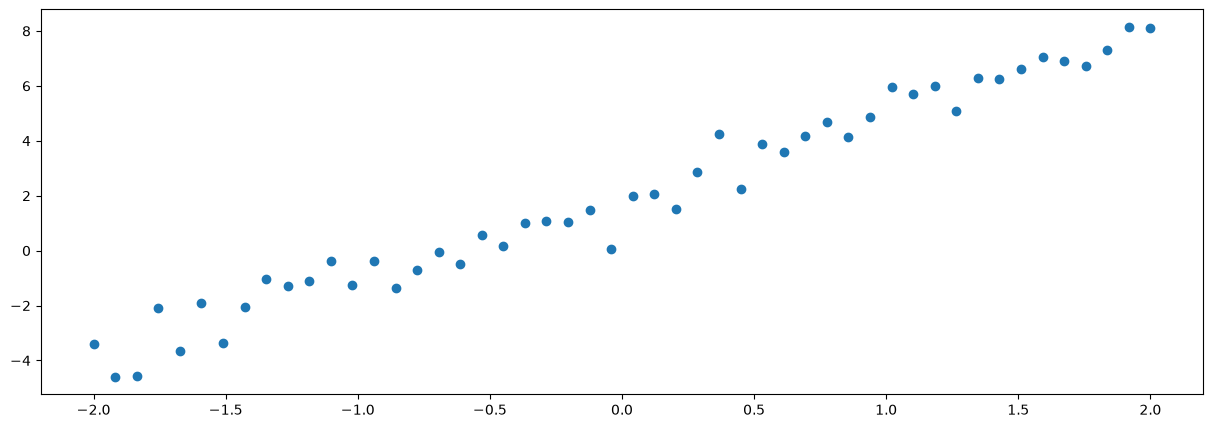

In [18]:
plt.figure(figsize=(15, 5))
plt.scatter(x, y)

In [19]:
import torch.nn as nn


In [20]:
model = nn.Linear(1, 1)

In [ ]:
# Trainning the model 
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)
epochs = 100
losses = [] # créer une liste pour stocker les valeurs de perte à chaque epoch
for epoch in range(epochs):
    y_pred = model(x)
    loss = loss_function(y, y_pred)
    optimizer.zero_grad() # Initialiser les gradient à zero 
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 100 == 0 :
        print(f"Epoch : {epoch} / {epochs}, loss : {loss.item()}") # Afficher le loss à chaque 100 epochs

Epoch : 0 / 100, loss : 0.38675984740257263


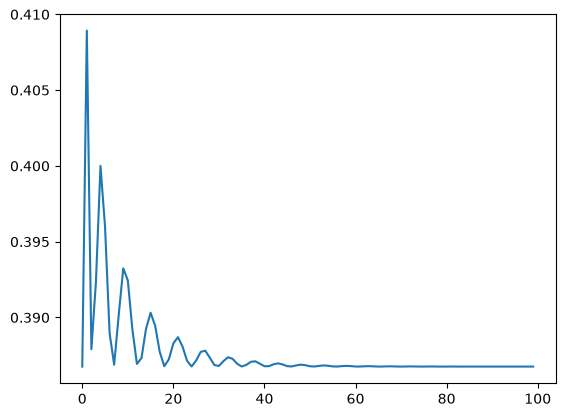

In [39]:
plt.plot(losses)

In [31]:
with torch.inference_mode():
    pred = model(x)

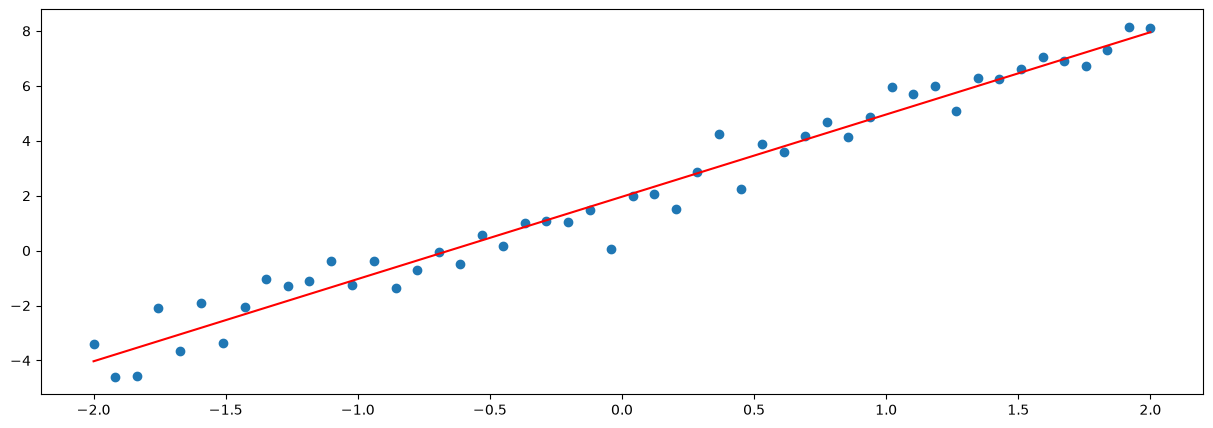

In [32]:
plt.figure(figsize=(15, 5))
plt.scatter(x, y)
plt.plot(x, pred, color="red")

In [26]:
from torcheval.metrics import R2Score 

In [33]:
# Calcule du taux de détermination (R²) pour évaluer la performance du modèle
r2_score = R2Score()
r2_score.update(y,pred)
score = r2_score.compute()


In [34]:
print(score)

tensor(0.9689)


## Créer un réseau de neurones et effectuer une passe avant (forward) pour visualiser le graphe de calcul

In [1]:
import torch
import torch.nn as nn
from torchviz import make_dot

In [2]:
# Créer un modèle simple avec une couche linéaire
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

In [3]:
# Affichage des résultats
print("Sortie :", y)
print("Poids : ", model.weight)
print("Biais : ", model.bias)


Sortie : tensor([[2.1986]], grad_fn=<AddmmBackward0>)
Poids :  Parameter containing:
tensor([[0.3737, 0.0841, 0.3984]], requires_grad=True)
Biais :  Parameter containing:
tensor([0.4616], requires_grad=True)


In [4]:
# Visualisation du graphe des opérations
dot = make_dot(y, params=dict(model.named_parameters()))
# Rendu du graphe des opérations et sauvegarde en format PNG
dot.render("graphe_operations", format="png", cleanup=True)

'graphe_operations.png'

# Construire un réseau de neurones

In [ ]:
# Créer un modèle de réseau de neurones multi-couches (MLP) avec PyTorch
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential( 
            nn.Linear(4,16),
            nn.ReLU(),
            nn.Linear(16,8),
            nn.ReLU(),
            nn.Linear(8,3)

        )
    def forward(self, x):
        return self.net(x)
model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [ ]:
# Créer un modèle séquentiel avec plusieurs couches linéaires et fonctions d'activation
# Plusieurs couches linéaires sont empilées les unes sur les autres, avec des fonctions d'activation ReLU entre elles. Le modèle prend en entrée un vecteur de taille 4 et produit un vecteur de taille 3 en sortie.
from torch.nn import Sequential


model = Sequential(
    nn.Linear(4,16),
    nn.ReLU(),
    nn.Linear(16,8),
    nn.ReLU(),
    nn.Linear(8,3)
)

print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)


### Fonction d'Activation

In [ ]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7, 4))
plt.plot(x.numpy(), relu.numpy(), label='ReLU')
